# 01 · Data quality and exploratory analysis

**Synthetic banking dataset. No Monzo customer data or real experiment.**

Question: are the records trustworthy enough to compare activation between randomised groups? We inspect the unit of observation before aggregation, keep denominator-changing decisions explicit, and use Polars throughout. Run `python run_pipeline.py` first if the derived outputs are absent.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import polars as pl
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / "config/simulation.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.common import config
pl.Config.set_tbl_rows(16)
pl.Config.set_tbl_cols(14)
print("Polars:", pl.__version__)


Polars: 2.0.0


## 1. Dataset inventory and reproducibility
Read the manifest and profile. Event rows are not users; transaction rows are not activated users.

In [2]:
manifest=json.loads((ROOT/'data/manifest.json').read_text())
display(pl.read_csv(ROOT/'data/processed/table_profile.csv'))
print('Synthetic:',manifest['synthetic'],'Seed:',manifest['seed'])
print('Raw bytes:',sum(x['bytes'] for x in manifest['files']))

Synthetic: True Seed: 20261017
Raw bytes: 91687262


table,rows,columns
str,i64,i64
"""users""",250000,5
"""assignments""",250000,4
"""events""",5901194,5
"""transactions""",698846,6
"""support""",16517,5
"""fraud""",982,5
"""tracking_issues""",31675,2


## 2. Schema and missing fields
A null user ID in telemetry is a quality problem. A null first-payment timestamp in the derived population is a valid non-activation outcome.

In [3]:
profile=pl.read_csv(ROOT/'data/processed/column_profile.csv')
display(profile)
display(profile.filter(pl.col('null_count')>0))
users=pl.scan_parquet(ROOT/'data/raw/users/*.parquet')
assignments=pl.scan_parquet(ROOT/'data/raw/assignments/*.parquet')
events=pl.scan_parquet(ROOT/'data/raw/events/*.parquet')
tx=pl.scan_parquet(ROOT/'data/raw/transactions/*.parquet')

table,column,dtype,null_count
str,str,str,i64
"""users""","""user_id""","""Int64""",0
"""users""","""signup_at""","""Datetime(time_unit='us', time_…",0
"""users""","""channel""","""String""",0
"""users""","""device""","""String""",0
"""users""","""age_band""","""String""",0
"""assignments""","""user_id""","""Int64""",0
"""assignments""","""variant""","""String""",0
"""assignments""","""assigned_at""","""Datetime(time_unit='us', time_…",0
…,…,…,…


table,column,dtype,null_count
str,str,str,i64
"""events""","""user_id""","""Int64""",2932


## 3. Key uniqueness and table grain

In [4]:
for name,lf,key in [('users',users,'user_id'),('assignments',assignments,'user_id'),('transactions',tx,'transaction_id'),('raw events',events,'event_id')]:
    print(name,lf.select(pl.len().alias('rows'),pl.col(key).n_unique().alias('distinct_keys')).collect().to_dicts())

users [{'rows': 250000, 'distinct_keys': 250000}]
assignments [{'rows': 250000, 'distinct_keys': 250000}]
transactions [{'rows': 698846, 'distinct_keys': 698846}]
raw events [{'rows': 5901194, 'distinct_keys': 5892394}]


## 4. Event taxonomy
Do not sum `account_funded` and `funding_confirmed` to count funded customers. Both describe the same funding moment.

In [5]:
display(events.group_by('event_name').len().sort('len',descending=True).collect())

event_name,len
str,u32
"""app_open""",2369247
"""onboarding_view""",1154200
"""payment_succeeded""",529269
"""help_view""",509304
"""verification_attempted""",280561
"""onboarding_started""",250000
"""balance_view""",247909
"""verification_completed""",190425
"""funding_confirmed""",153624


## 5. Duplicate, invalid and delayed records
Cleaning deduplicates event IDs and quarantines invalid references/times. Late arrivals remain usable at the final snapshot.

In [6]:
quality=json.loads((ROOT/'reports/quality_summary.json').read_text())
display(pl.read_csv(ROOT/'data/processed/event_quality.csv'))
print('Duplicate rows removed:',quality['duplicate_rows_removed'])
print('Late events retained:',quality['delayed_events_retained'])
clean=pl.scan_parquet(ROOT/'data/processed/events_clean.parquet')
display(events.select(((pl.col('ingested_at')-pl.col('event_at')).dt.total_seconds()/3600).quantile(.99).alias('p99_ingestion_hours')).collect())

Duplicate rows removed: 8800
Late events retained: 17605


quality_status,len
str,i64
"""before_signup""",1169
"""missing_user""",2932
"""orphan_user""",1169
"""valid""",5887124


p99_ingestion_hours
f64
0.165278


## 6. Independent injection audit
This log was not used by the cleaning logic. It allows us to check that known issues were caught.

In [7]:
display(pl.scan_parquet(ROOT/'data/raw/tracking_issues/*.parquet').group_by('issue').len().sort('issue').collect())

issue,len
str,u32
"""before_signup""",1169
"""delayed_ingestion""",17605
"""duplicate""",8800
"""missing_user""",2932
"""orphan_user""",1169


## 7. Acquisition mix

In [8]:
display(users.group_by('channel').len().with_columns((pl.col('len')/pl.col('len').sum()).alias('share')).sort('len',descending=True).collect())

channel,len,share
str,u32,f64
"""organic""",84586,0.338344
"""paid_search""",70500,0.282
"""referral""",54902,0.219608
"""social""",40012,0.160048


## 8. Device and synthetic age distribution
These categories are invented and do not describe Monzo customers.

In [9]:
display(users.group_by('device').len().collect()); display(users.group_by('age_band').len().sort('age_band').collect())

device,len
str,u32
"""Web""",19902
"""iOS""",107809
"""Android""",122289


age_band,len
str,u32
"""18–24""",59847
"""25–34""",95262
"""35–49""",64923
"""50+""",29968


## 9. Enrolment coverage and group sizes

first_signup,last_signup
datetime[μs],datetime[μs]
2026-01-01 00:00:29,2026-03-25 23:59:13


variant,len
str,u32
"""treatment""",125098
"""control""",124902


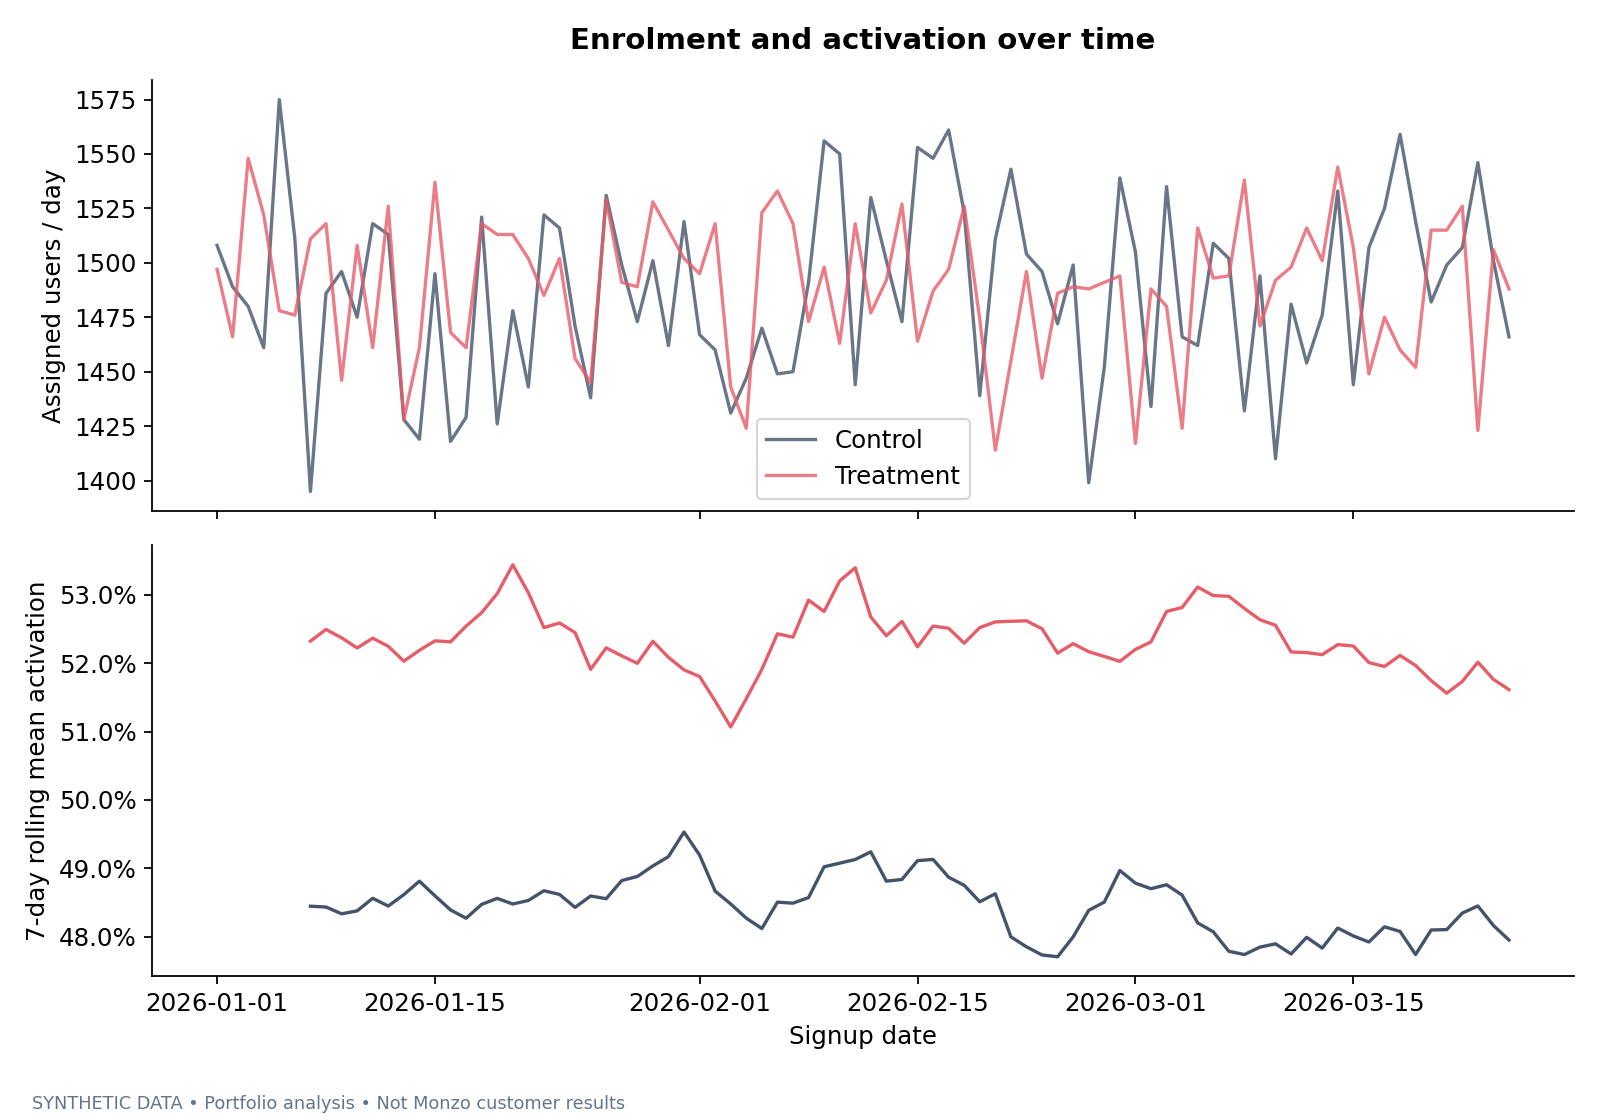

In [10]:
display(users.select(pl.col('signup_at').min().alias('first_signup'),pl.col('signup_at').max().alias('last_signup')).collect())
display(assignments.group_by('variant').len().collect())
display(Image(filename=str(ROOT/'reports/figures/03_daily_trends.png')))

## 10. Baseline balance
Inspect standardised differences rather than hunting for baseline p-values. Assignment is independent of the observed profile in the generator.

In [11]:
balance=pl.read_csv(ROOT/'data/dashboard/baseline_balance.csv'); display(balance); print('Largest absolute SMD:',balance['standardised_difference'].abs().max())

Largest absolute SMD: 0.0036398353696102063


dimension,category,control_share,treatment_share,standardised_difference
str,str,f64,f64,f64
"""channel""","""organic""",0.33913,0.337559,-0.003319
"""channel""","""paid_search""",0.28118,0.282818,0.00364
"""channel""","""referral""",0.219884,0.219332,-0.001334
"""channel""","""social""",0.159805,0.16029,0.001323
"""device""","""Android""",0.489071,0.48924,0.000338
"""device""","""Web""",0.079502,0.079714,0.00078
"""device""","""iOS""",0.431426,0.431046,-0.000768
"""age_band""","""18–24""",0.23918,0.239596,0.000976
"""age_band""","""25–34""",0.380466,0.381629,0.002394


## 11. Transactions: status, type and amount
Failed attempts must not contribute to activation or payment value.

kind,status,transactions,total_gbp,median_gbp,p99_gbp
str,str,u32,f64,f64,f64
"""funding""","""success""",153624,2.0407e8,1328.375,2477.31
"""payment""","""failed""",15953,1.0617e6,66.39,123.8
"""payment""","""success""",529269,8.3539e7,121.7,667.24


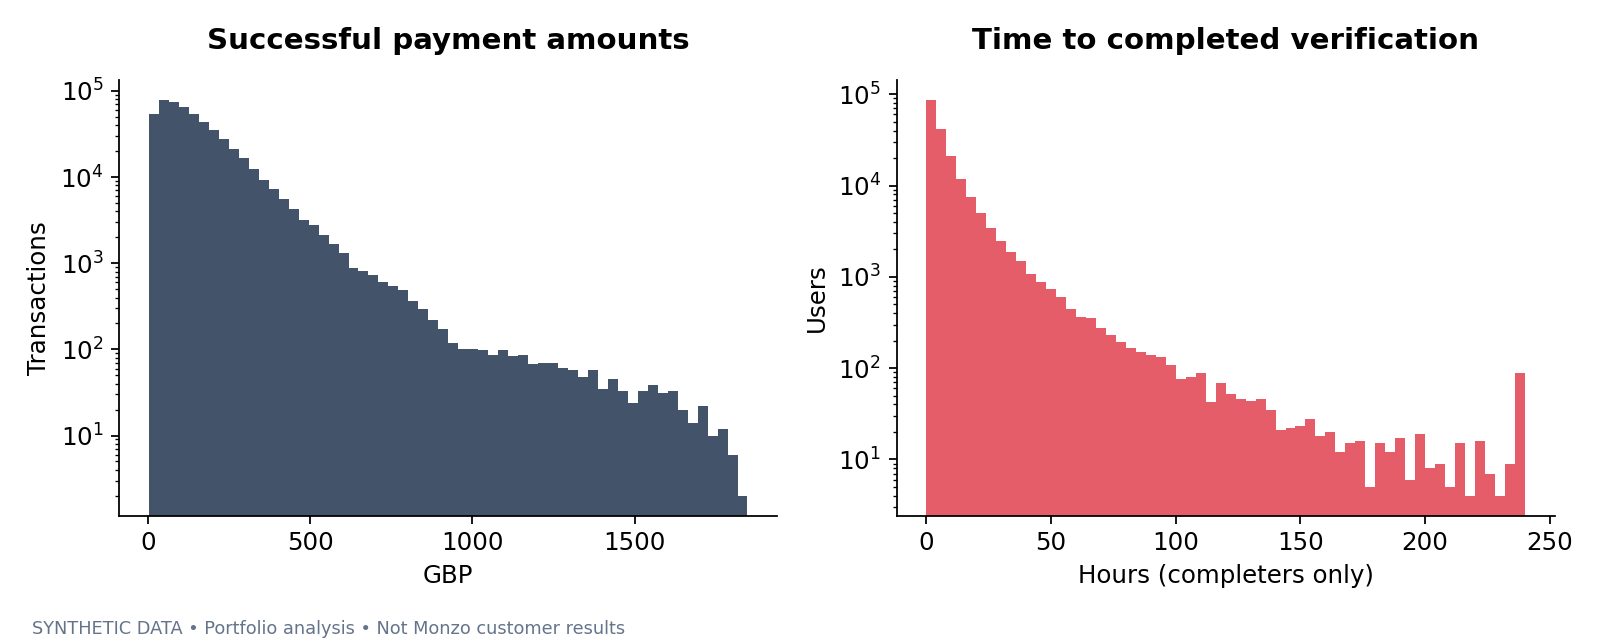

In [12]:
display(tx.group_by('kind','status').agg(pl.len().alias('transactions'),pl.col('amount_gbp').sum().alias('total_gbp'),pl.col('amount_gbp').median().alias('median_gbp'),pl.col('amount_gbp').quantile(.99).alias('p99_gbp')).sort('kind','status').collect())
display(Image(filename=str(ROOT/'reports/figures/07_distributions.png')))

## 12. Heavy users and verification retries
An event-heavy user must not get more weight in the experiment than a quiet user.

In [13]:
per_user=clean.group_by('user_id').len()
display(per_user.select(pl.col('len').min().alias('min_events'),pl.col('len').median().alias('median_events'),pl.col('len').quantile(.99).alias('p99_events'),pl.col('len').max().alias('max_events')).collect())
attempts=clean.filter(pl.col('event_name')=='verification_attempted').group_by('user_id').len()
display(attempts.group_by('len').agg(pl.len().alias('users')).sort('len').collect())

min_events,median_events,p99_events,max_events
u32,f64,f64,u32
4,23.0,37.0,51


len,users
u32,u32
1,219439
2,30561


## 13. Support and fraud proxies

In [14]:
display(pl.scan_parquet(ROOT/'data/raw/support/*.parquet').group_by('reason').agg(pl.len().alias('contacts'),pl.col('resolution_hours').median().alias('median_resolution_hours')).collect())
display(pl.scan_parquet(ROOT/'data/raw/fraud/*.parquet').group_by('flag_type').len().collect())

reason,contacts,median_resolution_hours
str,u32,f64
"""onboarding_error""",5494,8.58
"""verification_question""",11023,8.34


flag_type,len
str,u32
"""unusual_device""",326
"""amount_pattern""",335
"""velocity""",321


## 14. Relational and temporal integrity

In [15]:
checks=pl.read_csv(ROOT/'data/processed/sql_quality_checks.csv'); display(checks); assert checks['failures'].sum()==0

check_name,failures
str,i64
"""duplicate_users""",0
"""duplicate_assignments""",0
"""assignments_without_user""",0
"""users_without_assignment""",0
"""transaction_orphans""",0
"""duplicate_transactions""",0
"""funding_before_verification""",0
"""payment_before_funding""",0
"""negative_amount""",0


## Interpretation

The raw event table is intentionally imperfect. Cleaning preserves all assigned users and trustworthy transaction outcomes. We do not drop customers because they have bad ancillary telemetry. Amount distributions and app-return rates reflect generator choices; they are not banking benchmarks. The next notebook uses a single row per assigned user to avoid fan-out bias.